# Análise Exploratória e Subdivisão do Dataset

## Abertura e Avaliação dos metadados

In [91]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [92]:
accident_df = pd.read_csv("../ACCIDENT/metadata-real.csv")
accident_df.head()

,path,type,rollover,accident_time,accident_frame,center_x,center_y,x1,y1,x2,...,scene_layout,weather,day_time,quality,no_frames,duration,height,width,split_in_distribution,split_geo_aware
0,real_videos/Z4kg2Ev3vhk_00.mp4,rear-end,0,11.333,170,0.735971,0.324499,0.708077,0.271914,0.763865,...,highway,normal,night,Very_Poor,424,29.967,1080,1584,test,test
1,real_videos/unS0-TLF1ao_00.mp4,t-bone,0,2.560,64,0.440814,0.116778,0.366460,0.074969,0.515168,...,signalized_intersection,normal,night,Very_Poor,148,5.920,1080,1920,test,train
2,real_videos/UarP8qU1S-c_00.mp4,single,0,8.667,130,0.598330,0.239566,0.577213,0.221251,0.619448,...,highway,normal,night,Poor,222,15.333,2160,3840,train,test
3,real_videos/UarP8qU1S-c_01.mp4,single,0,2.034,30,0.643610,0.326142,0.610369,0.303103,0.676851,...,highway,normal,night,Poor,92,6.167,2160,3840,train,test
4,real_videos/nAXTthLfgtI_00.mp4,single,0,4.125,62,0.441961,0.263168,0.417832,0.249357,0.466090,...,highway,normal,night,Very_Poor,208,13.875,720,960,test,test


In [93]:
accident_df.describe()

,rollover,accident_time,accident_frame,center_x,center_y,x1,y1,x2,y2,no_frames,duration,height,width
count,2027.000000,2027.000000,2027.000000,2027.000000,2027.000000,2027.000000,2027.000000,2027.000000,2027.000000,2027.000000,2027.000000,2027.000000,2027.000000
mean,0.113962,5.565824,98.265417,0.495798,0.464480,0.432198,0.405071,0.559397,0.523889,377.426246,21.848133,806.638382,1319.592501
std,0.317843,4.464704,86.150707,0.204783,0.188448,0.210405,0.177255,0.213716,0.212712,225.265115,10.335567,246.826245,472.782933
min,0.000000,0.120000,2.000000,0.023328,0.024747,0.000000,0.000000,0.041714,0.044278,20.000000,1.300000,160.000000,314.000000
25%,0.000000,3.042000,47.000000,0.346901,0.323812,0.275121,0.272495,0.407432,0.366364,205.000000,11.633166,720.000000,960.000000
50%,0.000000,4.667000,76.000000,0.495380,0.446007,0.435258,0.389326,0.554758,0.497150,375.000000,26.826800,720.000000,1280.000000
75%,0.000000,6.729166,121.000000,0.643967,0.587581,0.588299,0.520445,0.711662,0.654174,449.000000,29.958000,1080.000000,1584.000000
max,1.000000,91.024267,954.000000,0.966932,0.969830,0.941287,0.941600,1.000000,1.000000,1610.000000,114.957446,2160.000000,3840.000000


In [94]:
num_samples = len(accident_df)
print(f"O dataset possui um total de {num_samples} amostras")

O dataset possui um total de 2027 amostras


In [95]:
accident_df.dtypes

path                         str
type                         str
rollover                   int64
accident_time            float64
accident_frame             int64
center_x                 float64
center_y                 float64
x1                       float64
y1                       float64
x2                       float64
y2                       float64
region                       str
scene_layout                 str
weather                      str
day_time                     str
quality                      str
no_frames                  int64
duration                 float64
height                     int64
width                      int64
split_in_distribution        str
split_geo_aware              str
dtype: object

In [96]:
print(f"Dados faltantes:", accident_df.isna().sum().sum())

Dados faltantes: 0


In [97]:
accident_classes = accident_df["type"].unique()
accident_classes

<StringArray>
['rear-end', 't-bone', 'single', 'head-on', 'sideswipe']
Length: 5, dtype: str

In [98]:
accident_df['rollover'].value_counts()

rollover
0    1796
1     231
Name: count, dtype: int64

In [99]:
accident_df['region'].unique()

<StringArray>
[    'Georgia',       'World',    'Virginia',     'Alabama',    'Arkansas',
   'Tennessee',         'USA',   'Minnesota',   'Wisconsin',        'Iowa',
     'Florida',    'New_York',      'Kansas',   'Louisiana',    'Maryland',
     'Unknown', 'Mississippi',      'Nevada',     'Seattle',         'UAE']
Length: 20, dtype: str

In [100]:
accident_df['scene_layout'].value_counts()

scene_layout
highway                         937
signalized_intersection         703
grade_separated_intersection    156
simple_intersection             100
city_street                      81
tunnel                           25
parking_lot                      17
roundabout                        8
Name: count, dtype: int64

In [101]:
accident_df['day_time'].value_counts()

day_time
day      1376
night     651
Name: count, dtype: int64

In [102]:
accident_df['split_in_distribution'].value_counts()

split_in_distribution
test     1520
train     507
Name: count, dtype: int64

Em relação aos clipes reais, o dataset ACCIDENT possui as seguintes colunas:

path -> caminho/identificador dos clipes reais.
type -> classe referente ao tipo de colisão (head-on, rear-end, t-bone, sideswipe ou single-vehicle), definido por voto majoritário entre 3 e 5 anotadores.
rollover -> ocorrência de capotamento no acidente.
accident_time -> tempo do primeiro contato visível.
accident_frame -> frame do primeiro contato visível. (Correspondente ao frame)
center_x, center_y -> centroides do impacto, normalizados entre 0 e 1 pela largura e altura do vídeo.
x1, y1, x2, y2 -> cantos da bounding box do acidente, normalizados entre 0 e 1 pela largura e altura do vídeo.
no_frames -> número total de frames
duration -> duração em segundos
height, width -> resolução do vídeo em pixels
region -> região de origem do vídeo
scene_layout -> tipo de cena
quality -> qualidade do vídeo
weather -> clima 
day_time -> período do dia (dia ou noite)
split_in_distribution -> distribuição train/test 25/75



## Análise Gráfica de Distribuição

In [103]:
numeric_columns = accident_df.select_dtypes(include="number").columns.tolist()
numeric_columns.remove('rollover')
numeric_columns

['accident_time',
 'accident_frame',
 'center_x',
 'center_y',
 'x1',
 'y1',
 'x2',
 'y2',
 'no_frames',
 'duration',
 'height',
 'width']

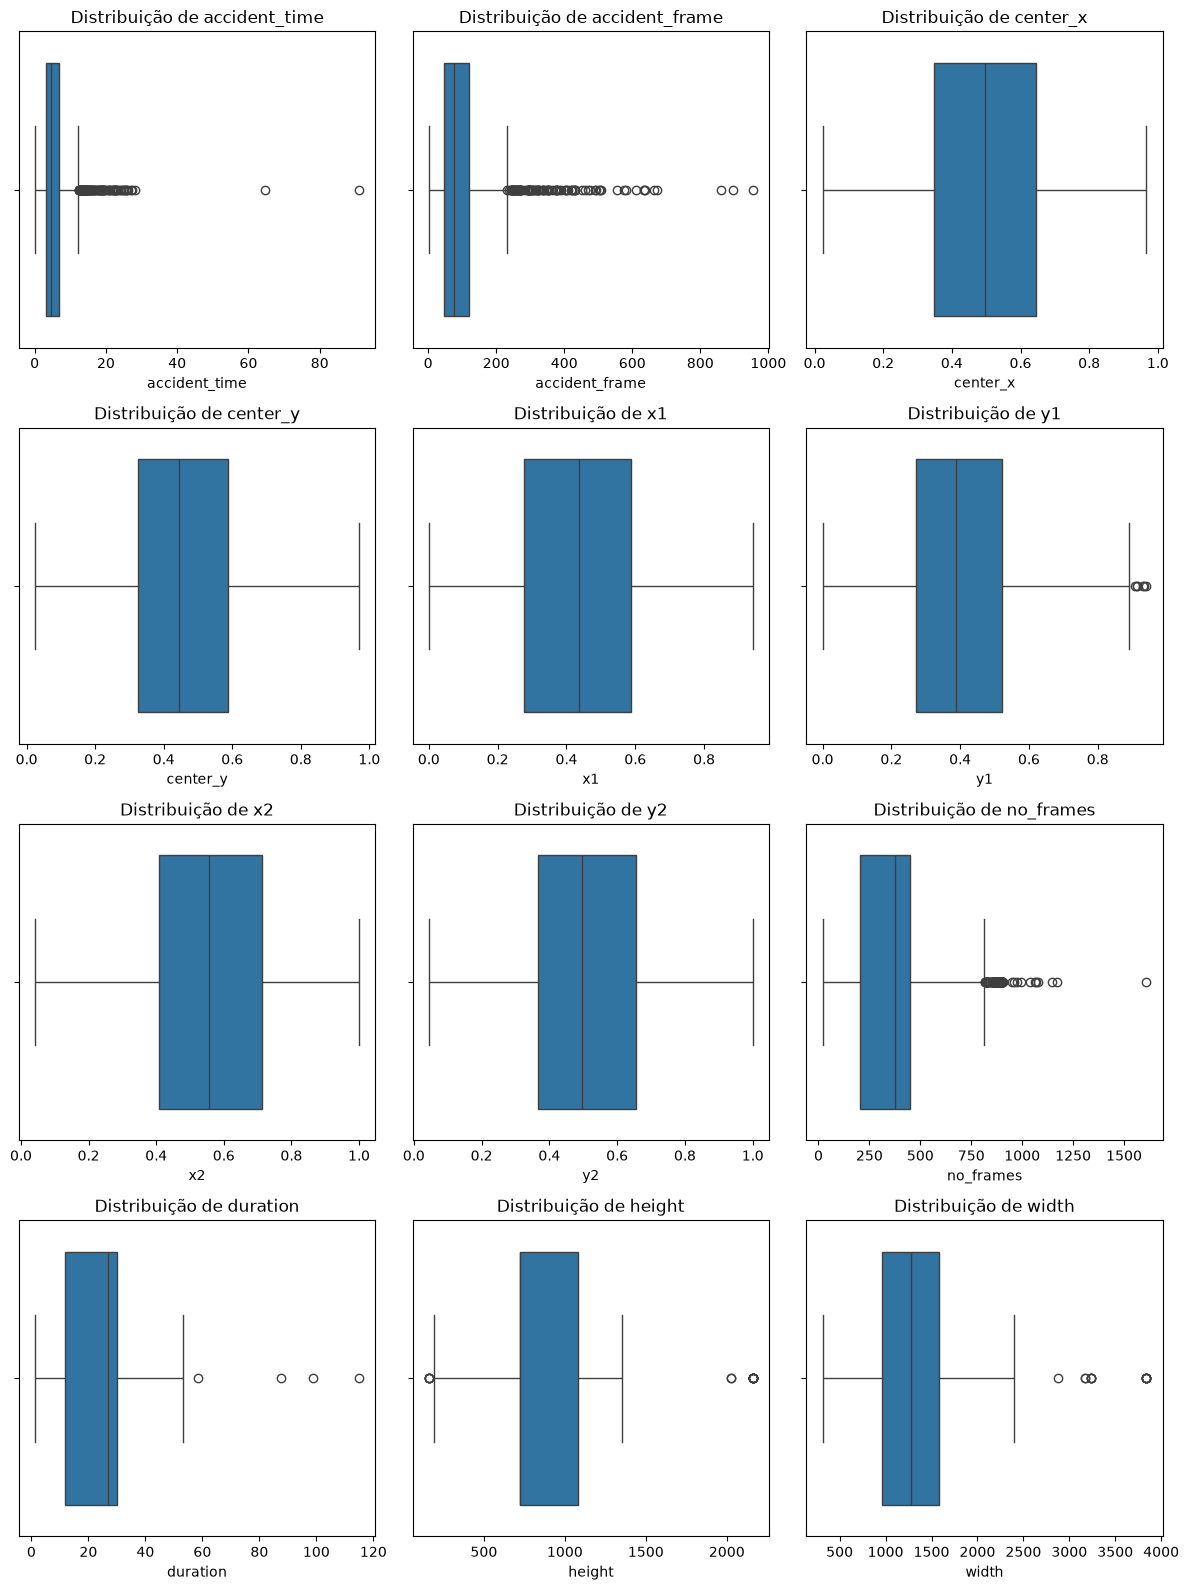

In [104]:
n_cols = 3 
n_rows = 4

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 4))
axes = axes.flatten()  

for i, col in enumerate(numeric_columns):
    sns.boxplot(data=accident_df, x=col, ax=axes[i])  
    axes[i].set_title(f'Distribuição de {col}')
    axes[i].set_xlabel(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [105]:
categorical_columns = accident_df.select_dtypes(include="str").columns.tolist()
categorical_columns.remove('path')
categorical_columns.remove('split_in_distribution')
categorical_columns.remove('split_geo_aware')
categorical_columns.append('rollover')

In [106]:
categorical_columns

['type',
 'region',
 'scene_layout',
 'weather',
 'day_time',
 'quality',
 'rollover']

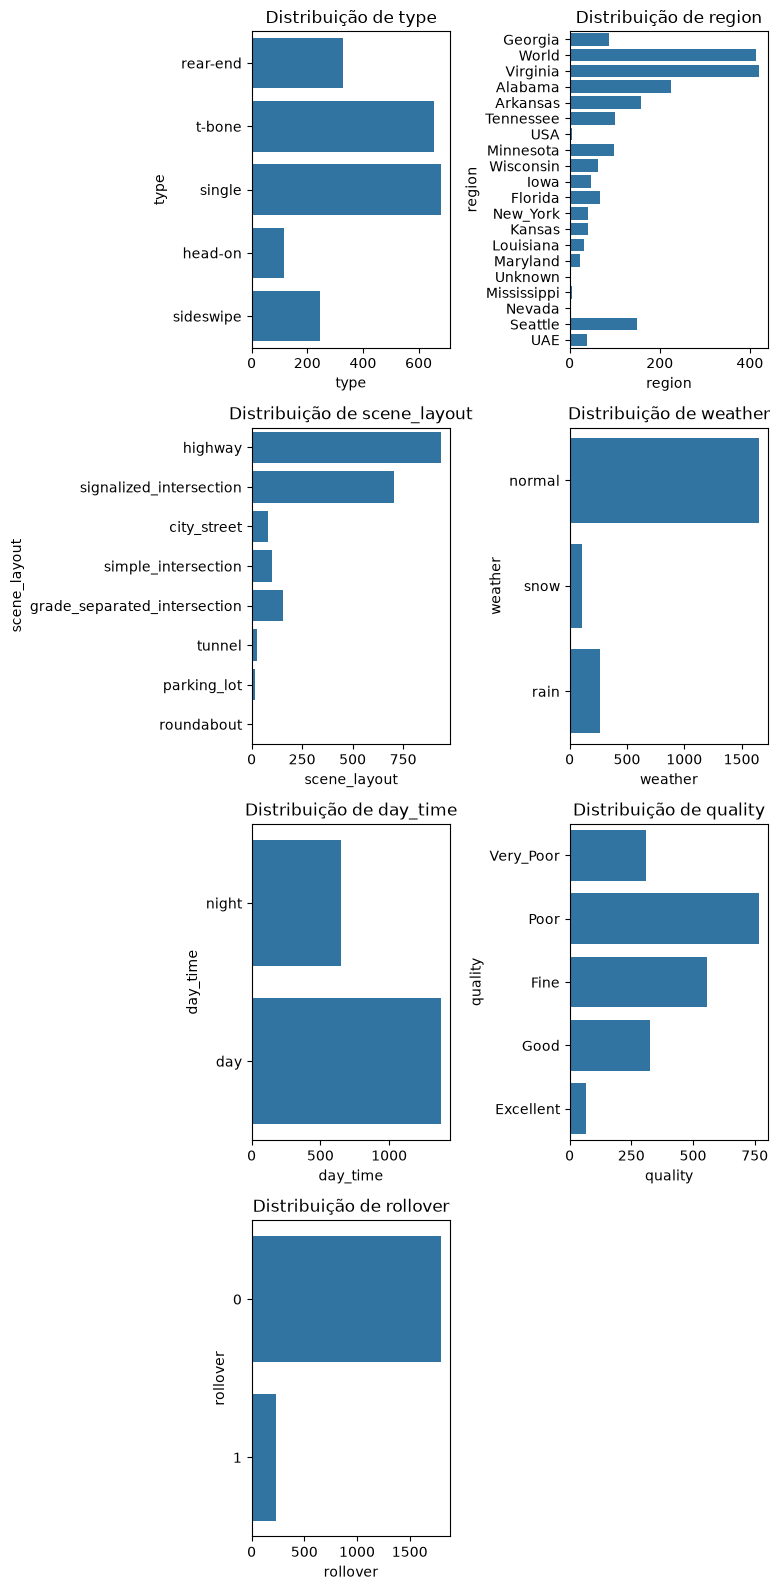

In [108]:
n_cols = 2
n_rows = 4

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 4))
axes = axes.flatten()  

for i, col in enumerate(categorical_columns):
    sns.countplot(data=accident_df, y=col, ax=axes[i])  
    axes[i].set_title(f'Distribuição de {col}')
    axes[i].set_xlabel(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Subdivisão do Dataset para validação de modelos

A seguir, será desenvolvida uma seleção estratificada de um subconjunto de vídeos reais do dataset ACCIDENT.

* Serão selecionados 100 vídeos do dataset: 20 de cada uma das classes de colisão (coluna 'type');
* Dentro de cada classe, a amostragem é proporcional à distribuição em relação à day_time, quality e scene_layout para que o subconjunto permaneça representativo.

In [109]:
df = accident_df.copy()
df['fps'] = df['no_frames'] / df['duration']

df['time_frame_diff_s'] = (df['accident_time'] - df['accident_frame'] / df['fps']).abs()

df['grid_col'] = np.clip((df['center_x'] * 3).astype(int), 0, 2) + 1
df['grid_row'] = np.clip((df['center_y'] * 3).astype(int), 0, 2) + 1

df.head()

,path,type,rollover,accident_time,accident_frame,center_x,center_y,x1,y1,x2,...,no_frames,duration,height,width,split_in_distribution,split_geo_aware,fps,time_frame_diff_s,grid_col,grid_row
0,real_videos/Z4kg2Ev3vhk_00.mp4,rear-end,0,11.333,170,0.735971,0.324499,0.708077,0.271914,0.763865,...,424,29.967,1080,1584,test,test,14.148897,0.682071,3,1
1,real_videos/unS0-TLF1ao_00.mp4,t-bone,0,2.560,64,0.440814,0.116778,0.366460,0.074969,0.515168,...,148,5.920,1080,1920,test,train,25.000000,0.000000,2,1
2,real_videos/UarP8qU1S-c_00.mp4,single,0,8.667,130,0.598330,0.239566,0.577213,0.221251,0.619448,...,222,15.333,2160,3840,train,test,14.478576,0.311784,2,1
3,real_videos/UarP8qU1S-c_01.mp4,single,0,2.034,30,0.643610,0.326142,0.610369,0.303103,0.676851,...,92,6.167,2160,3840,train,test,14.918113,0.023022,2,1
4,real_videos/nAXTthLfgtI_00.mp4,single,0,4.125,62,0.441961,0.263168,0.417832,0.249357,0.466090,...,208,13.875,720,960,test,test,14.990991,0.010817,2,1


In [120]:
import cv2
from pathlib import Path

ROOT = Path.cwd().parent
DATA = ROOT / 'ACCIDENT'

def video_ok(file: Path, check_readable: bool) -> bool:
    """True se o arquivo existe (e, opcionalmente, abre com o OpenCV)."""
    if not file.exists():
        return False
    if not check_readable:
        return True
    cap = cv2.VideoCapture(str(file))
    good = cap.isOpened() and cap.read()[0]
    cap.release()
    return bool(good)

def filter_videos(df: pd.DataFrame, video_root: str, check_readable: bool = True) -> pd.DataFrame:
    """Descarta vídeos inexistentes (e, opcionalmente, ilegíveis)."""
    root = Path(video_root)
    df = df.copy()
    df["video_file"] = [str(root / p) for p in df["path"]]

    mask = np.array([video_ok(root / p, check_readable) for p in df["path"]])
    print(f"[info] vídeos utilizáveis: {mask.sum()} / {len(df)}")
    if (~mask).any():
        print(f"[aviso] {(~mask).sum()} vídeos ausentes/ilegíveis serão ignorados "
              f"(ex.: {df.loc[~mask, 'path'].head(3).tolist()})")
    return df[mask].reset_index(drop=True)


df_ok = filter_videos(df, video_root=DATA, check_readable=True)
df_ok.head()

[info] vídeos utilizáveis: 2027 / 2027


,path,type,rollover,accident_time,accident_frame,center_x,center_y,x1,y1,x2,...,duration,height,width,split_in_distribution,split_geo_aware,fps,time_frame_diff_s,grid_col,grid_row,video_file
0,real_videos/Z4kg2Ev3vhk_00.mp4,rear-end,0,11.333,170,0.735971,0.324499,0.708077,0.271914,0.763865,...,29.967,1080,1584,test,test,14.148897,0.682071,3,1,C:\Users\reisi\accident\ACCIDENT\real_videos\Z...
1,real_videos/unS0-TLF1ao_00.mp4,t-bone,0,2.560,64,0.440814,0.116778,0.366460,0.074969,0.515168,...,5.920,1080,1920,test,train,25.000000,0.000000,2,1,C:\Users\reisi\accident\ACCIDENT\real_videos\u...
2,real_videos/UarP8qU1S-c_00.mp4,single,0,8.667,130,0.598330,0.239566,0.577213,0.221251,0.619448,...,15.333,2160,3840,train,test,14.478576,0.311784,2,1,C:\Users\reisi\accident\ACCIDENT\real_videos\U...
3,real_videos/UarP8qU1S-c_01.mp4,single,0,2.034,30,0.643610,0.326142,0.610369,0.303103,0.676851,...,6.167,2160,3840,train,test,14.918113,0.023022,2,1,C:\Users\reisi\accident\ACCIDENT\real_videos\U...
4,real_videos/nAXTthLfgtI_00.mp4,single,0,4.125,62,0.441961,0.263168,0.417832,0.249357,0.466090,...,13.875,720,960,test,test,14.990991,0.010817,2,1,C:\Users\reisi\accident\ACCIDENT\real_videos\n...


In [125]:
N_PER_CLASS = 20   

subset = (df_ok.groupby("type")
               .sample(n=N_PER_CLASS, random_state=42)
               .sample(frac=1, random_state=42)     
               .reset_index(drop=True))
subset.insert(0, "sample_id", [f"acc_{i:03d}" for i in range(len(subset))])
subset["type"].value_counts()

type
t-bone       20
sideswipe    20
single       20
rear-end     20
head-on      20
Name: count, dtype: int64

In [126]:
subset

,sample_id,path,type,rollover,accident_time,accident_frame,center_x,center_y,x1,y1,...,duration,height,width,split_in_distribution,split_geo_aware,fps,time_frame_diff_s,grid_col,grid_row,video_file
0,acc_000,real_videos/xYbFnmG3-Og_00.mp4,t-bone,0,3.333000,49,0.708456,0.763898,0.617019,0.710300,...,29.958000,720,960,test,test,14.553709,0.033839,3,3,C:\Users\reisi\accident\ACCIDENT\real_videos\x...
1,acc_001,real_videos/uwdOQc-iC_c_00.mp4,sideswipe,0,5.667000,84,0.318698,0.440228,0.284251,0.414647,...,28.583000,720,960,test,test,14.729035,0.036021,1,2,C:\Users\reisi\accident\ACCIDENT\real_videos\u...
2,acc_002,real_videos/Pjuu3TEEonY_00.mp4,single,0,4.600000,137,0.195419,0.166544,0.166219,0.149455,...,10.533000,1080,1620,test,test,25.728662,0.724801,1,1,C:\Users\reisi\accident\ACCIDENT\real_videos\P...
3,acc_003,real_videos/8j-qfY6_Bxg_00.mp4,sideswipe,0,3.958333,59,0.183820,0.385592,0.096443,0.253362,...,13.291666,720,1056,test,test,14.971788,0.017588,1,2,C:\Users\reisi\accident\ACCIDENT\real_videos\8...
4,acc_004,real_videos/oWLWFTK4QdU_01.mp4,sideswipe,0,7.700000,193,0.826780,0.225896,0.814580,0.208451,...,10.200000,1080,1920,test,test,25.000000,0.020000,3,1,C:\Users\reisi\accident\ACCIDENT\real_videos\o...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,acc_095,real_videos/BBFzGfSLEZE_00.mp4,single,1,3.267000,49,0.563313,0.477812,0.534031,0.459204,...,30.000000,1080,1920,test,test,15.000000,0.000333,2,2,C:\Users\reisi\accident\ACCIDENT\real_videos\B...
96,acc_096,real_videos/EyZo7F2P35A_00.mp4,single,0,4.567000,68,0.205747,0.341745,0.186974,0.324201,...,29.967000,1080,1920,test,test,14.983148,0.028568,1,2,C:\Users\reisi\accident\ACCIDENT\real_videos\E...
97,acc_097,real_videos/YiQToVQInNw_00.mp4,head-on,0,2.569233,61,0.409519,0.628001,0.345965,0.531379,...,5.905900,720,1280,test,train,24.043753,0.032191,2,2,C:\Users\reisi\accident\ACCIDENT\real_videos\Y...
98,acc_098,real_videos/EN-JKUXkwPQ_6_00.mp4,t-bone,0,3.320000,67,0.391345,0.141233,0.322293,0.112376,...,7.280000,360,480,train,train,22.802198,0.381687,2,1,C:\Users\reisi\accident\ACCIDENT\real_videos\E...


In [127]:
subset.to_csv('accident_subset_100.csv', index=False)